In [ ]:
BRANCH = "main"

%cd /tmp
!rm -rf damage-detection
!git clone -b {BRANCH} https://github.com/azrairemd/damage-detection.git
%cd damage-detection
!pip install -q -r requirements.txt
!pip install -q -e .

/tmp
Cloning into 'damage-detection'...
remote: Enumerating objects: 262, done.
remote: Counting objects: 100% (101/101), done.
remote: Compressing objects: 100% (86/86), done.
remote: Total 262 (delta 25), reused 49 (delta 14), pack-reused 161 (from 1)
Receiving objects: 100% (262/262), 12.77 MiB | 26.16 MiB/s, done.
Resolving deltas: 100% (104/104), done.
/tmp/damage-detection
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for damage-detection (pyproject.toml) ... done


In [3]:
import os
import shutil
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import cv2
from pathlib import Path
import segmentation_models_pytorch as smp
from torch.utils.data import DataLoader, Subset

from src.models.baseline_unet import BaselineUNet
from src.data.dataset import XBDDataset
from src.metrics.xview2 import XView2Metric
from src.losses.combined_loss import CombinedLoss
from src.losses.weights import compute_class_weights
from src.data.masks import get_mask_path
from src.train import fit, train_one_epoch, validate
from src.utils.config import load_config

In [11]:
device = "cuda" if torch.cuda.is_available() else "cpu"

In [12]:
config = load_config("configs/baseline.yaml")
data = config["data"]
train_cfg = config["training"]
loss_cfg = config["loss"]

# data
train_ds = XBDDataset(data["train_split"], data["xbd_root"], data["mask_root"],
                      train=True, crop_size=data["crop_size"])
val_ds = XBDDataset(data["val_split"], data["xbd_root"], data["mask_root"], train=False)

# data loader
train_loader = DataLoader(train_ds, batch_size=train_cfg["batch_size"], shuffle=True,
                          num_workers=train_cfg["num_workers"], drop_last=True)
val_loader = DataLoader(val_ds, batch_size=train_cfg["val_batch_size"], shuffle=False,
                        num_workers=train_cfg["num_workers"])

# model, loss and optimizer
model = BaselineUNet(encoder=config["model"]["encoder"]).to(device)

loss_fn = CombinedLoss(alpha=torch.tensor(loss_cfg["class_weights"]),
                       gamma=loss_cfg["gamma"], lam=loss_cfg["lam"])

optimizer = torch.optim.AdamW(model.parameters(), lr=train_cfg["learning_rate"])

print("Train batches:", len(train_loader), " Val batches:", len(val_loader))

Train batches: 827  Val batches: 1104


## Full Training - Baseline Model (post)

### 1. Test training - to find max_epochs for full training

In [7]:
from torch.utils.data import Subset

# a separate model, so that the real training starts from scratch
test_model = BaselineUNet(encoder=config["model"]["encoder"]).to(device)
test_optimizer = torch.optim.AdamW(test_model.parameters(), lr=train_cfg["learning_rate"])
test_scaler = torch.amp.GradScaler("cuda")

# 40 train batches and 40 val batches
small_train_loader = DataLoader(Subset(train_ds, range(320)), batch_size=train_cfg["batch_size"],
                                shuffle=True, num_workers=train_cfg["num_workers"], drop_last=True)
small_val_loader = DataLoader(Subset(val_ds, range(80)), batch_size=train_cfg["val_batch_size"],
                              num_workers=train_cfg["num_workers"])

start = time.time()
train_loss = train_one_epoch(test_model, small_train_loader, loss_fn, test_optimizer, device, test_scaler)
train_time = time.time() - start

start = time.time()
val = validate(test_model, small_val_loader, device)
val_time = time.time() - start

print(f"40 train batches: {train_time:.0f} s   loss {train_loss:.4f}")
print(f"40 val batches:   {val_time:.0f} s   score {val['score']:.4f}")

# estimate for the full data
epoch_min = (train_time / 40 * len(train_loader) + val_time / 40 * len(val_loader)) / 60
print(f"\nEstimated time per epoch: {epoch_min:.1f} min")
print(f"Estimated time for {train_cfg['max_epochs']} epochs: {epoch_min * train_cfg['max_epochs'] / 60:.1f} hours")

40 train batches: 56 s   loss 0.5515
40 val batches:   13 s   score 0.0115

Estimated time per epoch: 25.5 min
Estimated time for 50 epochs: 21.2 hours


**Time estimate**

To choose `max_epochs` for the full training, the duration of one epoch was estimated on a small subset:

| | 40 batches | Per batch | Full data | Estimated time |
|---|---|---|---|---|
| Train | 147 s | 3.7 s | × 827 | ~51 min |
| Validation | 33 s | 0.8 s | × 1,104 | ~15 min |
| **One epoch** | | | | **~66 min** |

With `max_epochs = 50`, the full training would take about **55 hours**, which exceeds both the Kaggle time limit for a single run.

**Options to reduce the training time:**

| Option | Change | Expected effect | Result |
|---|---|---|---|
| More data loading workers | `num_workers`: 2 → 4 | Up to ~2× faster data loading | Epoch time ~66 min → ~21 min |
| Automatic mixed precision (AMP) | Float16 computations on the GPU | Up to ~2× faster GPU computations, lower memory usage | Validation 1.4× faster (18 s → 13 s), but training not faster (38 s → 56 s), since training is limited by data loading, not by the GPU. Kept for faster validation and lower memory usage. |
| Fewer epochs | `max_epochs`: 50 → 20 | Directly reduces the total training time (patience: 10 → 4) | Chosen: with ~30 min per epoch (including a safety margin), at most ~10 hours |

### 1.1 to reduce the estimated time - num_workers

In [ ]:
print("CPU cores:", os.cpu_count())

There is no benefit to setting `num_workers` to a value greater than the number of processors. Each worker uses one processor. 
- CPU cores: 4

So `num_workers` value is changed in config/baseline.aml

### 1.2 to reduce the estimated time - automatic mixed precision
**AMP added** to `src/train.py`:
- The forward pass of the model is computed in float16 (`torch.autocast`), which is much faster on T4 GPUs.
- The model weights, the loss and the weight updates stay in float32 for numerical stability.
- A `GradScaler` scales the loss before backpropagation so that small gradients do not become zero in float16.

**Decision:** 
- `num_workers = 4`
- AMP enabled
- `max_epochs = 20` (patience = 4).

# Full Training

In [ ]:
out_dir = train_cfg["out_dir"]
os.makedirs(out_dir, exist_ok=True)
shutil.copy("configs/baseline.yaml", os.path.join(out_dir, "config.yaml"))

start = time.time()
best = fit(model, train_loader, val_loader, loss_fn, optimizer, device,
           max_epochs=train_cfg["max_epochs"], out_dir=out_dir)

print(f"Best val score: {best:.4f}")
print(f"Total time: {(time.time() - start) / 3600:.1f} hours")

**Baseline results**
- Best validation xView2 score: **0.6095** at epoch 11 (localization F1 0.717, damage F1 0.563).
- Training stopped at epoch 15 by early stopping (no improvement for 4 epochs, patience = 20% of 20 epochs). T
- Total time: 2.2 hours (~9 min per epoch with `num_workers = 4` and AMP).
- The training loss decreases steadily (0.48 → 0.39), while the validation score fluctuates strongly (e.g. 0.53 → 0.40 → 0.54). The fluctuations come almost entirely from the damage F1, which is the harmonic mean of the four damage classes and is therefore very sensitive to the weakest class.
- No clear sign of overfitting: the last epochs (0.587–0.588) are close to the best score.

**Training history**

| Epoch | Train loss | Val score | Loc F1 | Dmg F1 | New best? | Epochs without improvement |
|---|---|---|---|---|---|---|
| 1 | 0.4808 | 0.1903 | 0.6232 | 0.0047 | ✅ | 0 |
| 2 | 0.4472 | 0.1900 | 0.6111 | 0.0096 | | 1 |
| 3 | 0.4359 | 0.2580 | 0.6843 | 0.0753 | ✅ | 0 |
| 4 | 0.4288 | 0.3270 | 0.6849 | 0.1736 | ✅ | 0 |
| 5 | 0.4211 | 0.4833 | 0.6902 | 0.3946 | ✅ | 0 |
| 6 | 0.4153 | 0.4891 | 0.7050 | 0.3966 | ✅ | 0 |
| 7 | 0.4116 | 0.5311 | 0.6944 | 0.4612 | ✅ | 0 |
| 8 | 0.4079 | 0.3962 | 0.6724 | 0.2779 | | 1 |
| 9 | 0.4023 | 0.5358 | 0.7070 | 0.4624 | ✅ | 0 |
| 10 | 0.4026 | 0.5368 | 0.6833 | 0.4740 | ✅ | 0 |
| **11** | **0.3993** | **0.6095** | **0.7170** | **0.5634** | ✅ **best** | **0** |
| 12 | 0.3943 | 0.5607 | 0.7191 | 0.4928 | | 1 |
| 13 | 0.3943 | 0.4628 | 0.6943 | 0.3636 | | 2 |
| 14 | 0.3916 | 0.5870 | 0.7152 | 0.5321 | | 3 |
| 15 | 0.3897 | 0.5879 | 0.7202 | 0.5312 | | **4 → early stopping** |

**Best model:** epoch 11 (saved as `best.pt`). Training stopped at epoch 15 because the validation score did not improve for 4 epochs (patience = 20% of `max_epochs` = 20).

**Per-class F1 at the best epoch (11)**

| Class | F1 |
|---|---|
| No damage | 0.826 |
| Destroyed | 0.644 |
| Major damage | 0.611 |
| Minor damage | **0.371** |
| **Damage F1 (harmonic mean)** | **0.563** |

**Findings**
- **Minor damage is by far the hardest class** (F1 0.371), as expected from the EDA and the literature: minor damage is visually subtle in satellite images.
- **Order of learning:** no-damage and destroyed are already recognized after the first epoch (F1 0.81 and 0.63), major damage is learned gradually (0.07 → 0.61) and minor damage is learned slowest (0.00 → 0.37).
- Destroyed buildings are recognized very early, possibly because they come mostly from wildfire events with strong visual cues (burn scars). This will be checked with Grad-CAM in Phase 8.

# Training curves

In [4]:
log = pd.read_csv("reports/logs/baseline_log.csv")
best_epoch = log.loc[log["val_score"].idxmax(), "epoch"]

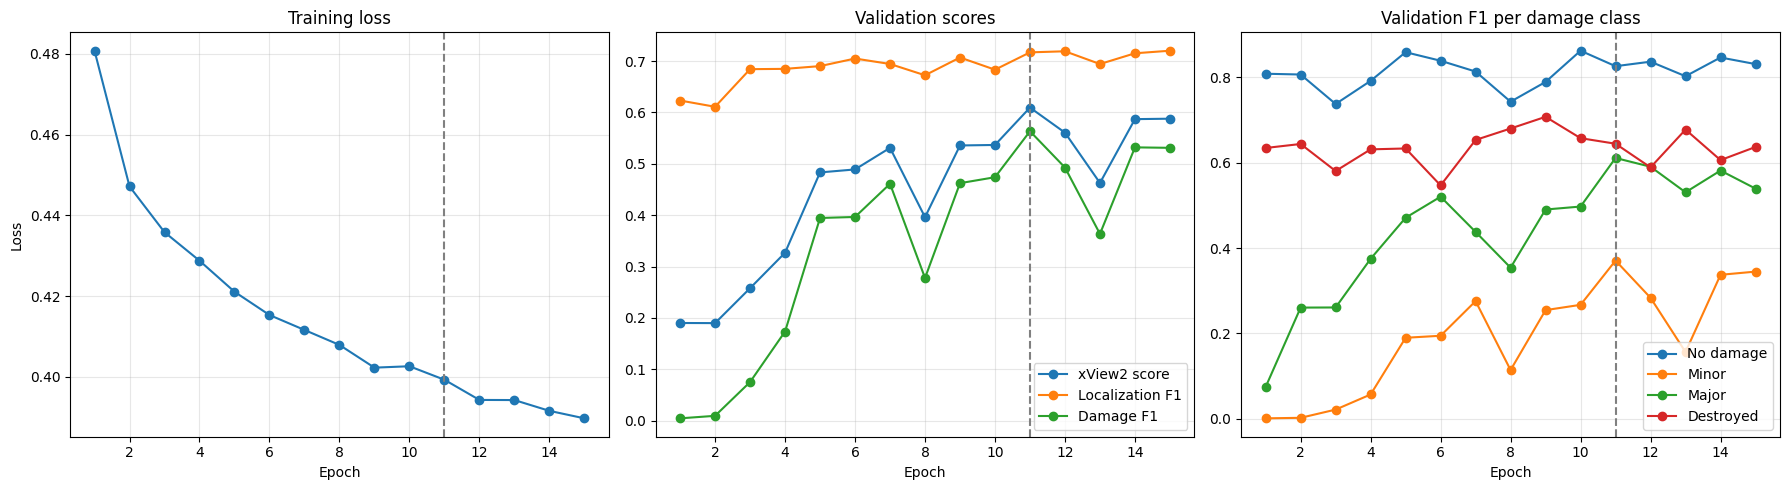

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. training loss
axes[0].plot(log["epoch"], log["train_loss"], marker="o")
axes[0].set_title("Training loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")

# 2. validation scores
axes[1].plot(log["epoch"], log["val_score"], marker="o", label="xView2 score")
axes[1].plot(log["epoch"], log["f1_loc"], marker="o", label="Localization F1")
axes[1].plot(log["epoch"], log["f1_dmg"], marker="o", label="Damage F1")
axes[1].set_title("Validation scores")
axes[1].set_xlabel("Epoch")
axes[1].legend()

# 3. per-class F1
for column, name in [("f1_no_damage", "No damage"), ("f1_minor", "Minor"),
                     ("f1_major", "Major"), ("f1_destroyed", "Destroyed")]:
    axes[2].plot(log["epoch"], log[column], marker="o", label=name)
axes[2].set_title("Validation F1 per damage class")
axes[2].set_xlabel("Epoch")
axes[2].legend()

for ax in axes:
    ax.axvline(best_epoch, color="gray", linestyle="--")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("/kaggle/working/baseline_curves.png", dpi=150)
plt.show()

**Training curves**
- **Training loss** the training loss decreases steadily at every epoch (0.48 → 0.39).
  
- **Validation score:** the localization F1 is stable (0.62 → 0.72), while the damage F1 fluctuates strongly. The xView2 score follows the damage F1, since the damage F1 has a weight of 0.7.
- **F1 per damage class:** no-damage and destroyed are recognized from the first epochs, major damage improves steadily, and minor damage is the lowest and most unstable class. 
- The best epoch (11, dashed line) is also the epoch with the highest minor-damage F1.